(100, 112, 112)


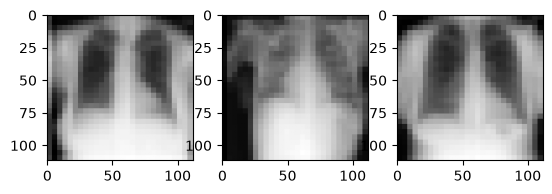

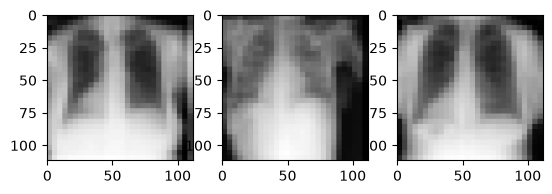

In [75]:
# PROBLEM 1: X-Ray Images

import PIL
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sp
import urllib.request

# download the image
imgURL = "https://raw.githubusercontent.com/<user>/<repo>/<branch>/<path>/medmnist_xray_grid.png"

# Load it into PIL
img = Image.open("medmnist_xray_grid.png")
grid = np.array(img)

# grid is 1120 x 1120 and img has 10 x 10 photos
n_rows = 10
n_cols = 10
H,W = grid.shape
h,w = int(H/n_rows), int(W/n_cols) # find dims of each photo 

# change 1120 x 1120 to 10 112 10 112 for 10 tile rows and 10 tile columns and 112 pixels per photo in each dimension (row x column)
xrays = grid.reshape(n_rows, h, n_cols, w)
# change to 10 10 112 112 
xrays = xrays.swapaxes(1, 2)
# flatten tile axes into one axis of 100 images 100 112 112
xrays = xrays.reshape(-1, h, w)
print(xrays.shape)

# check some images against the given image 
fig, axes = plt.subplots(1,3)
axes[0].imshow(xrays[0], cmap = 'gray')
axes[1].imshow(xrays[5], cmap = 'gray')
axes[2].imshow(xrays[10], cmap = 'gray')
plt.show()

# need to flip by column pixel axis which is 3rd axis
xrays_flip = np.flip(xrays,axis = 2)

# check flipped images
fig, axes = plt.subplots(1,3)
axes[0].imshow(xrays_flip[0], cmap = 'gray')
axes[1].imshow(xrays_flip[5], cmap = 'gray')
axes[2].imshow(xrays_flip[10], cmap = 'gray')
plt.show()

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/arnavchaturvedi/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/arnavchaturvedi/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


<function matplotlib.pyplot.show(close=None, block=None)>

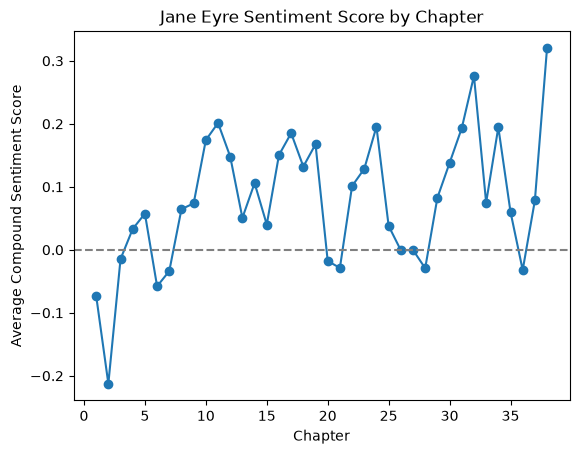

In [93]:
# PROBLEM 2: Jane Eyre Sentiment by Chapter
import re
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import nltk
from bs4 import BeautifulSoup
from nltk.sentiment import SentimentIntensityAnalyzer
nltk.download('punkt_tab')
nltk.download('vader_lexicon')

# bring book from downloaded text
with open("Jane Eyre _ Project Gutenberg.html", encoding="utf-8") as f:
    html = f.read()
text = BeautifulSoup(html, "html.parser").get_text()

# split into 38 chapters and remove "Preface" and "Note to third edition"
chars = re.split(r"CHAPTER [IVXLC]+",text)
chapters = [c for c in chars]
chapters = chapters[1:] # remove everything before chapter 1
chapters[-1] = chapters[-1].split("*** END OF")[0] #remove non book text at end 
# print(len(chapters))
# print(chapters[37])

# do sentiment analysis
sentiment = SentimentIntensityAnalyzer().polarity_scores
scores = []
#need to score by sentence within each chapter. Scoring by full chapter does not give a detailed score and goes directly to 1 or -1
for c in chapters:
    sentences = nltk.tokenize.sent_tokenize(c.replace("\n", " ")) #remove spaces
    sentence_scores = [sentiment(s)["compound"] for s in sentences]
    scores.append(np.mean(sentence_scores))

# make plot
plt.plot(range(1, len(scores)+1), scores,marker="o")
plt.axhline(0, color="gray", linestyle="--") # plot 0 line
plt.xlabel("Chapter")
plt.ylabel("Average Compound Sentiment Score")
plt.title("Jane Eyre Sentiment Score by Chapter")
plt.show
         